# Más allá: pruebas de ML y equidad con tamaño y potencia medidos, una referencia por permutación para el cambio y una nula Beta-Binomial para la cobertura


**Pregunta:** ¿Con qué frecuencia se activan las pruebas de aprendizaje automático y de equidad cuando nada anda mal, y con cuál cuando se planta un defecto, y cambian esas tasas las correcciones hechas a las pruebas de cobertura, de desplazamiento y de situación?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 02, 04 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- definir el **tamaño** (la tasa de rechazo cuando nada está mal) y la **potencia** (la tasa de rechazo contra un defecto plantado) de una prueba de validación, y dar cada uno con su error estándar de Monte Carlo;
- medir el tamaño de la prueba de cobertura conforme dividida bajo una nula binomial y bajo la nula Beta-Binomial que usa el motor, en tres razones de ventana de prueba a ventana de calibración;
- medir con qué frecuencia una regla de caída fija del AUC se activa en la peor submuestra cuando no hay cambio, y compararla con la referencia por permutación del motor, en tamaño y potencia;
- medir el tamaño y la potencia de la luz de la prueba de situación en los dos puntos de corte ámbar;
- ver las pruebas corregidas en las filas versionadas de los casos C20 y C21, y decir qué respalda esta evidencia y qué no.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import plants as fair_plants
from riskvalidation.fairness import situation
from riskvalidation.ml import conformal, plants, robustness

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
YN = {True: "sí", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

- **Datos simulados nulos y con defecto plantado de los generadores del propio motor**: puntajes intercambiables para la prueba de cobertura, `CovariateShiftPlant` (cambio 0 es la nula, cambio 2 planta un cambio) para la prueba de resiliencia y `ThresholdBiasPlant` (brecha 0 es la nula, brecha 0,8 un sesgo plantado) para la prueba de situación. Sintéticos, con semilla, sin clase de licencia. Cada simulación es lo bastante pequeña para correr en menos de dos minutos en este notebook; las corridas mayores pertenecen a los propios conjuntos de tamaño y potencia del motor.
- **Dos documentos versionados** que llevan las pruebas corregidas en uso (propietario: este repositorio): `data/derived/C20/fed-shift.json` (un modelo LightGBM sobre los datos de quiebras polacas de UCI, CC BY 4.0, clase mirror-allowed, bajo desplazamientos sintéticos dimensionados por las carteras corporativas de la Reserva Federal; sus filas conformes guardan ambos valores p y su fila de resiliencia sus 199 sorteos por permutación) y `data/derived/C21/pair-2018-19.json` (la comparación HMDA de Delaware, su fila de prueba de situación con el punto de corte ámbar que usa). La primera celda del Método los abre e imprime la versión del motor que los horneó.

In [2]:
# Abrir los dos documentos versionados e imprimir la versión del motor que horneó cada uno
fed_path = ROOT / "data" / "derived" / "C20" / "fed-shift.json"
hmda_path = ROOT / "data" / "derived" / "C21" / "pair-2018-19.json"
fed = json.loads(fed_path.read_text(encoding="utf-8"))
hmda = json.loads(hmda_path.read_text(encoding="utf-8"))
print("C20 fed-shift horneado con riskvalidation", fed["provenance"]["riskvalidation_version"], end=" ")
print("| C21 pair-2018-19", hmda["provenance"]["riskvalidation_version"])

C20 fed-shift horneado con riskvalidation 1.0.1 | C21 pair-2018-19 1.0.1


## Método

Una prueba de validación es una regla de decisión, y una regla de decisión tiene tasas de error. Para una prueba que rechaza al nivel $\alpha = 0{,}05$:

$$\text{tamaño} = P(\text{rechazar} \mid \text{nada está mal}), \qquad \text{potencia} = P(\text{rechazar} \mid \text{un defecto de severidad conocida}).$$

Una prueba con un tamaño sobre su nivel nominal levanta falsas alarmas y enseña a un equipo a ignorarla; una prueba de baja potencia pasa por alto lo que se hizo para encontrar. Ambos son propiedades de la regla y de los tamaños de muestra, y ninguno lo enuncia la descripción de las pruebas del dossier. Sobre $R$ simulaciones independientes la tasa de rechazo $\hat{r}$ tiene el error estándar de Monte Carlo $\sqrt{\hat{r}(1-\hat{r})/R}$, que las celdas imprimen junto a cada tasa. Todo sorteo aleatorio tiene semilla.

### Paso 1: el tamaño de la prueba de cobertura, binomial contra Beta-Binomial

Con puntajes intercambiables la cobertura verdadera dada la ventana de calibración es $\mathrm{Beta}(k, n_{\mathrm{cal}}+1-k)$ (notebook 04). Una prueba que compara el conteo cubierto $c$ de $m$ puntos de prueba con $\mathrm{Binomial}(m, 1-\alpha)$ trata la cobertura como el número fijo $1-\alpha$ e ignora esa variación; la variación es pequeña cuando $m \ll n_{\mathrm{cal}}$ y grande cuando no. El tamaño aproximado de la prueba binomial es $2\bigl(1-\Phi(1{,}96/\sqrt{1 + m/n_{\mathrm{cal}}})\bigr)$: 5% cuando $m/n_{\mathrm{cal}} \to 0$ y sobre eso en otro caso. El motor devuelve ambos valores p; la celda siguiente saca 1.500 réplicas intercambiables en cada una de tres razones de $m$ a $n_{\mathrm{cal}}$ (0,1, 1 y 4) y cuenta con qué frecuencia cada valor p queda bajo 0,05.

Antes de la simulación, una réplica muestra lo que esta repite. La celda siguiente saca los puntajes de calibración y
los de prueba de una ventana intercambiable, toma el cuantil conforme, cuenta los puntos de prueba cubiertos e imprime
ambos valores p.

In [3]:
# Una réplica intercambiable: el cuantil, el conteo cubierto y ambos valores p
demo = np.random.default_rng(7)
n_cal, m = 2000, 2000
q = conformal.split_conformal_quantile(demo.random(n_cal), 0.1)
covered = demo.random(m) <= q
sets = np.column_stack([covered, np.zeros(m, dtype=bool)])
result = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
print(f"cuantil {q:.4f} | cobertura {result.coverage:.4f} | k {result.k} | meta {result.target:.2f}")
print(f"p Beta-Binomial {result.p_value:.4f} | p binomial {result.p_value_binomial:.4f}")

cuantil 0.8974 | cobertura 0.8945 | k 1801 | meta 0.90
p Beta-Binomial 0.5264 | p binomial 0.4122


La celda siguiente repite esa réplica 1.500 veces para cada una de las tres razones de ventanas.

In [4]:
# Tamaño de la prueba de cobertura bajo intercambiabilidad: cuántas veces cada valor p cae bajo 0,05
rng = np.random.default_rng(1)
REPS = 1500
conformal_size = {}
print(
    f"{'n_cal':>6s} {'m':>5s} {'m / n_cal':>9s} | {'tamaño binomial':>16s} {'ee de Monte Carlo':>18s}",
    end=" ",
)
print(f"| {'tamaño Beta-Binomial':>20s} {'ee de Monte Carlo':>18s}")
for n_cal, m in ((20000, 2000), (2000, 2000), (1000, 4000)):
    below_binomial = below_beta = 0
    for _ in range(REPS):
        q = conformal.split_conformal_quantile(rng.random(n_cal), 0.1)
        covered = rng.random(m) <= q
        sets = np.column_stack([covered, np.zeros(m, dtype=bool)])
        result = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
        below_binomial += result.p_value_binomial < 0.05
        below_beta += result.p_value < 0.05
    sizes = (below_binomial / REPS, below_beta / REPS)
    conformal_size[(n_cal, m)] = sizes
    errors = [float(np.sqrt(s * (1 - s) / REPS)) for s in sizes]
    print(f"{n_cal:6d} {m:5d} {m / n_cal:9.1f} | {sizes[0]:16.4f} {errors[0]:18.4f}", end=" ")
    print(f"| {sizes[1]:20.4f} {errors[1]:18.4f}")

 n_cal     m m / n_cal |  tamaño binomial  ee de Monte Carlo | tamaño Beta-Binomial  ee de Monte Carlo
 20000  2000       0.1 |           0.0600             0.0061 |               0.0460             0.0054
  2000  2000       1.0 |           0.1587             0.0094 |               0.0440             0.0053
  1000  4000       4.0 |           0.3893             0.0126 |               0.0427             0.0052


Los tres tamaños de cada prueba se comparan mejor contra el nivel nominal que como columnas de números. La celda
siguiente los dibuja, con la línea de 0,05.

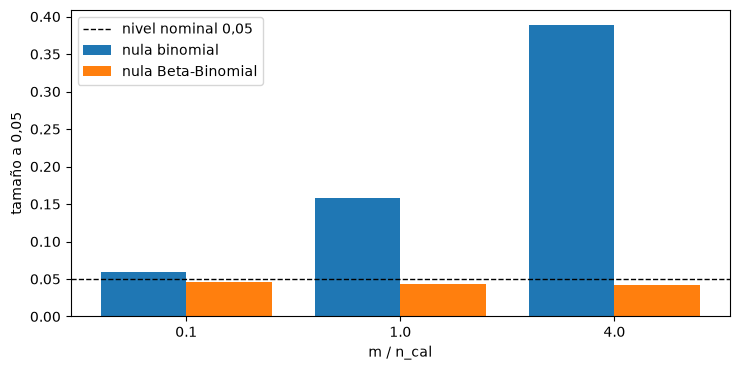

In [5]:
# Tamaño de la prueba de cobertura según la razón de ventanas, con nula binomial y con nula Beta-Binomial
ratios = [f"{m / n:.1f}" for n, m in conformal_size]
position = np.arange(len(ratios))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(position - 0.2, [s[0] for s in conformal_size.values()], width=0.4, label="nula binomial")
ax.bar(position + 0.2, [s[1] for s in conformal_size.values()], width=0.4, label="nula Beta-Binomial")
ax.axhline(0.05, color="black", linestyle="--", linewidth=1, label="nivel nominal 0,05")
ax.set_xticks(position)
ax.set_xticklabels(ratios)
ax.set_xlabel("m / n_cal")
ax.set_ylabel("tamaño a 0,05")
ax.legend()
fig.tight_layout()
plt.show()

La nula binomial rechaza en 0,0600, 0,1587 y 0,3893 a medida que la ventana de prueba pasa de una décima de la de
calibración a cuatro veces, que es la tasa de falsas alarmas que un equipo aprendería a ignorar. La nula Beta-Binomial se
mantiene en 0,0460, 0,0440 y 0,0427, bajo la línea punteada en las tres razones y nunca sobre ella. La forma binomial
tiene un tamaño cercano al correcto solo cuando la ventana de prueba es pequeña frente a la de calibración, porque
ignora que el cuantil de calibración es en sí aleatorio.

### Paso 2: la prueba de resiliencia, una caída fija contra una referencia por permutación

El notebook 02 mostró que la caída del AUC en la peor submuestra según el puntaje de cambio es positiva incluso donde nada se movió, porque esa submuestra es una región del espacio de variables y el AUC en un rango restringido es menor. Una regla que lee la caída contra un corte **fijo** se activa entonces sobre un modelo estable. Dos celdas miden esto, primero una réplica y luego todas, en la planta de cambio con cambio 0 (la nula) y con cambio 2 (un cambio plantado de la primera covariable), sobre 60 réplicas de 600 filas de desarrollo y 250 de evaluación, con el peor 25% como submuestra. En cada réplica registra la caída bruta y el valor p por permutación de la referencia del motor (aquí 39 sorteos en lugar de los 199 por omisión, para mantener corta la simulación; el menor valor p es entonces 0,025). Informa la tasa de falsa alarma de dos cortes fijos (el primero una caída sobre 0,05 puntos de AUC, el segundo sobre 0,10) y de la regla por permutación (p como máximo 0,05), y las mismas tres tasas bajo el cambio plantado, que son las potencias.

In [6]:
# Una réplica con desplazamiento 2: la submuestra peor, la caída cruda y el valor p por permutación
plant = plants.CovariateShiftPlant(n=600, shift=2.0, features=[0], seed=1000)
d = plant.sample()
x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=0)
worst = robustness.worst_subsample_performance(plant.predict, x_eval, y_eval, score, 0.25)
reference = robustness.shift_development_reference(
    plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, 39, seed=0
)
print(f"AUC todas las filas {worst.auc_full:.4f} | AUC submuestra peor {worst.auc:.4f}")
print(f"caída cruda {reference.observed_drop:.4f} | p por permutación {reference.p_value:.4f}")
print(f"extracciones 39 | media nula {np.mean(reference.null_drops):.4f}")

AUC todas las filas 0.8891 | AUC submuestra peor 0.8584
caída cruda 0.0307 | p por permutación 0.2500
extracciones 39 | media nula 0.0047


La celda siguiente repite esa réplica 60 veces con desplazamiento 0 y con desplazamiento 2, y registra la caída cruda y el valor p.

In [7]:
# Caída cruda y valor p por permutación de la prueba de la peor submuestra en 60 réplicas con desplazamiento 0 y 2
shift_rates, drop_samples = {}, {}
print(f"{'desplaz.':>8s} {'réplicas':>10s} {'caída media':>11s} {'pct. 95':>9s}", end=" ")
print(f"| {'caída sobre 0,05':>22s} {'caída sobre 0,10':>22s} {'p permutación <= 0,05':>24s}")
for shift in (0.0, 2.0):
    drops, p_values = [], []
    for i in range(60):
        plant = plants.CovariateShiftPlant(n=600, shift=shift, features=[0], seed=1000 + i)
        d = plant.sample()
        x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
        score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=i)
        try:
            reference = robustness.shift_development_reference(
                plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, 39, seed=i
            )
        except robustness.SingleClassSubsampleError:
            continue
        drops.append(reference.observed_drop)
        p_values.append(reference.p_value)
    drops, p_values = np.array(drops), np.array(p_values)
    rates = ((drops > 0.05).mean(), (drops > 0.10).mean(), (p_values <= 0.05).mean())
    shift_rates[shift], drop_samples[shift] = (rates, len(drops)), drops
    print(f"{shift:8.1f} {len(drops):10d} {drops.mean():11.4f} {np.percentile(drops, 95):9.4f}", end=" ")
    print(f"| {rates[0]:22.4f} {rates[1]:22.4f} {rates[2]:24.4f}")
print(
    "ee de Monte Carlo de una tasa cercana al nivel nominal con 60 réplicas:",
    round(float(np.sqrt(0.05 * 0.95 / 60)), 4),
)

desplaz.   réplicas caída media   pct. 95 |       caída sobre 0,05       caída sobre 0,10    p permutación <= 0,05
     0.0         60      0.0119    0.1203 |                 0.2000                 0.0833                   0.0667
     2.0         60      0.1348    0.2778 |                 0.8500                 0.6667                   0.5000
ee de Monte Carlo de una tasa cercana al nivel nominal con 60 réplicas: 0.0281


Las tasas de las tres reglas quedan determinadas por dónde caen las caídas crudas respecto de los cortes. La celda
siguiente dibuja las 60 caídas crudas de cada diseño como histogramas, con los dos cortes fijos como líneas verticales.

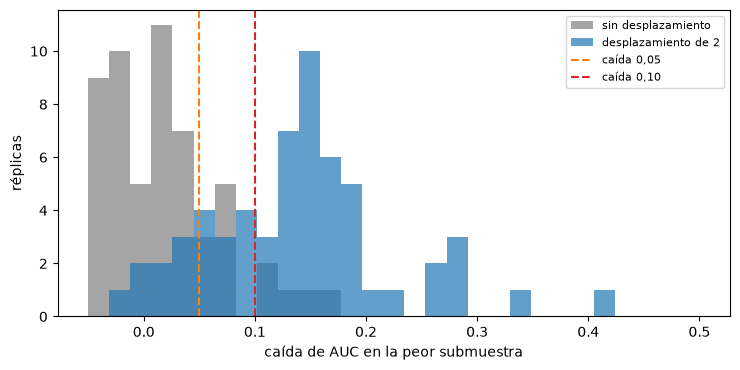

In [8]:
# Caída cruda de AUC de la peor submuestra en 60 réplicas, sin y con un desplazamiento plantado
bins = np.linspace(-0.05, 0.5, 30)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(drop_samples[0.0], bins=bins, alpha=0.7, color="tab:gray", label="sin desplazamiento")
ax.hist(drop_samples[2.0], bins=bins, alpha=0.7, color="tab:blue", label="desplazamiento de 2")
ax.axvline(0.05, color="tab:orange", linestyle="--", label="caída 0,05")
ax.axvline(0.10, color="tab:red", linestyle="--", label="caída 0,10")
ax.set_xlabel("caída de AUC en la peor submuestra")
ax.set_ylabel("réplicas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Sin desplazamiento las caídas no están centradas en cero: su media es 0,0119 y su percentil 95 es 0,1203, de modo que
una buena parte queda a la derecha de la línea de 0,05 (0,2000) y algunas más allá de 0,10 (0,0833). Con el
desplazamiento plantado el histograma se mueve a una media de 0,1348, y los cortes fijos lo detectan en 0,8500 y 0,6667
de las réplicas. Los cortes fijos compran entonces su potencia con falsas alarmas, mientras que la regla por permutación
mantiene la tasa de falsas alarmas en 0,0667 y detecta el desplazamiento en 0,5000, al precio de una referencia gruesa
con 39 extracciones.

### Paso 3: la luz de la prueba de situación, en dos puntos de corte

La prueba de situación devuelve, para los denunciantes del grupo protegido, cuántos son significativos al nivel $\alpha = 0{,}05$ con el intervalo de Wald unilateral del notebook 07. Incluso sin efecto de grupo algunos denunciantes son significativos por azar, así que la luz lee la **proporción** de denunciantes significativos contra un punto de corte: verde hasta el corte, ámbar sobre él, nunca roja. Un punto de corte es una convención, y la manera de elegirlo es medir la distribución de la proporción bajo la nula y bajo un sesgo plantado. Siguen dos celdas: una réplica de 400 solicitantes y luego 200 réplicas de 400 solicitantes sacadas con la planta de sesgo de umbral del motor con brecha 0 (la nula: la decisión depende solo de las covariables) y brecha 0,8 (el grupo protegido aprobado con un punto de corte menor), corre la prueba ceteris paribus con $k = 30$ e informa con qué frecuencia la proporción supera el primer corte (0,10) y el segundo (0,20), en el orden de las dos columnas.

In [9]:
# Una réplica de prueba de situación con la planta de sesgo de umbral con brecha 0,8
draw = fair_plants.ThresholdBiasPlant(n=400, gap=0.8, seed=2000).draw_default()
result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
share = result.n_significant / result.n_complainants
print(f"denunciantes {result.n_complainants} | casos {result.n_cases}", end=" ")
print(f"| significativos {result.n_significant} | proporción {share:.4f}")

denunciantes 218 | casos 186 | significativos 167 | proporción 0.7661


La celda siguiente repite la prueba en 200 réplicas con brecha 0 y brecha 0,8 y cuenta cuántas veces la proporción cruza cada corte.

In [10]:
# Proporción de denunciantes significativos en 200 réplicas con brecha 0 y 0,8, y cuántas veces supera cada corte
situation_rates = {}
print(f"{'brecha':>5s} {'réplicas':>10s} {'proporción media':>16s}", end=" ")
print(f"| {'proporción sobre 0,10':>24s} {'proporción sobre 0,20':>24s}")
for gap in (0.0, 0.8):
    shares = []
    for i in range(200):
        draw = fair_plants.ThresholdBiasPlant(n=400, gap=gap, seed=2000 + i).draw_default()
        result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
        shares.append(result.n_significant / result.n_complainants)
    shares = np.array(shares)
    situation_rates[gap] = ((shares > 0.10).mean(), (shares > 0.20).mean())
    print(f"{gap:5.1f} {len(shares):10d} {shares.mean():16.4f}", end=" ")
    print(f"| {situation_rates[gap][0]:24.4f} {situation_rates[gap][1]:24.4f}")

brecha   réplicas proporción media |    proporción sobre 0,10    proporción sobre 0,20
  0.0        200           0.0398 |                   0.0850                   0.0150
  0.8        200           0.7338 |                   1.0000                   1.0000


## Estado del arte

La práctica que encontró la investigación para estas tres pruebas, con su brecha:

- **Cobertura conforme.** El dossier (C.7, l.1019 a 1028) prescribe la cobertura empírica sobre datos fuera de tiempo contra $1-\alpha$ "(prueba binomial sobre indicadores de cobertura)". Angelopoulos y Bates (2021) y Vovk, Gammerman y Shafer (2022) dan la garantía $P(Y \in C(X)) \ge 1-\alpha$ bajo intercambiabilidad; no describen el tamaño de una prueba de validación construida sobre una ventana de calibración finita. MAPIE y PiML (Reliability) implementan la forma dividida.
- **Resiliencia al cambio.** La prueba Resilience de PiML y el dossier (C.7, l.1013 a 1015) evalúan el desempeño en la peor submuestra según un puntaje de cambio y en ventanas fuera de tiempo; el dossier da la construcción y ninguna regla para decidir que una caída es demasiado grande.
- **Pruebas de situación.** Alvarez y Ruggieri (2025) dan el estadístico y el intervalo unilateral y dejan al usuario la decisión de cuántos denunciantes significativos son demasiados.

Ninguna de las herramientas del notebook 08 informa las tasas de rechazo de estas reglas sobre datos de verdad conocida.

## Más allá del estado del arte

Lo que el producto agrega, reclamado como **BS-10** en el SDD: las tres pruebas llevan las correcciones que decidieron las revisiones del motor, y el producto muestra, con las funciones del propio motor sobre datos plantados, la tasa de error que cada corrección elimina.

1. La prueba de cobertura lee la ley **Beta-Binomial** del conteo cubierto dado el tamaño de calibración, y conserva el valor p binomial del dossier a su lado.
2. La luz de resiliencia lee una **referencia por permutación** de las filas de desarrollo (199 sorteos por omisión), no una caída fija.
3. El punto de corte ámbar de la prueba de situación es **0,20**, fijado sobre un tamaño y una potencia medidos.

Las filas versionadas muestran las pruebas corregidas en uso. La celda siguiente imprime las ventanas conformes de la variante de la Reserva Federal con ambos valores p, la fila de resiliencia con sus sorteos y su resumen nulo, y la fila de prueba de situación con el punto de corte que usó.

In [11]:
# Las filas corregidas versionadas: ambos valores p conformes, las extracciones de resiliencia y el corte de situación
for t in [t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage"]:
    x = t["extras"]
    print(f"{t['segment']:28s} n_cal {x['n_cal']} m {t['n']:6d} p Beta-Binomial {t['p_value']:.3g}", end=" ")
    print(f"| binomial {x['p_value_binomial']:.3g} | luz {LIGHT[t['light']]}")
row = next(t for t in fed["tests"] if t["test_id"] == "ml.shift_resilience")
x = row["extras"]
print("resiliencia:", row["segment"], "| caída", round(row["metric"], 4), "| p", row["p_value"])
print("extracciones", x["shift_permutations"], "| media nula", round(x["null_mean"], 4), end=" ")
print("| percentil 95 nulo", round(x["null_p95"], 4), "|", LIGHT[row["light"]])
st = next(t for t in hmda["tests"] if t["test_id"] == "fair.situation_testing")
print("prueba de situación: proporción de denunciantes significativos", round(st["metric"], 4))
print("puntos de corte", st["extras"]["thresholds"]["amber"], "|", LIGHT[st["light"]])

window:baseline              n_cal 1471 m   3151 p Beta-Binomial 0.523 | binomial 0.313 | luz verde
window:fed-higher-risk-x0.25 n_cal 1471 m   3151 p Beta-Binomial 2.13e-35 | binomial 3.69e-127 | luz rojo
window:fed-higher-risk-x0.5  n_cal 1471 m   3151 p Beta-Binomial 4.56e-52 | binomial 1.19e-194 | luz rojo
window:fed-higher-risk-x1    n_cal 1471 m   3151 p Beta-Binomial 0.0372 | binomial 0.000258 | luz ámbar
window:pooled                n_cal 1471 m  12604 p Beta-Binomial 2.86e-20 | binomial 2.16e-207 | luz rojo
resiliencia: fed-higher-risk-x1 | caída 0.0857 | p 0.005
extracciones 199 | media nula 0.0007 | percentil 95 nulo 0.0243 | rojo
prueba de situación: proporción de denunciantes significativos 0.2629
puntos de corte 0.2 | ámbar


### La evidencia, dibujada

La última figura pone lado a lado la tasa de falsas alarmas y la potencia de cada regla: los dos cortes fijos de caída y
la referencia por permutación de la prueba de resiliencia, y los dos puntos de corte ámbar de la luz de la prueba de
situación.

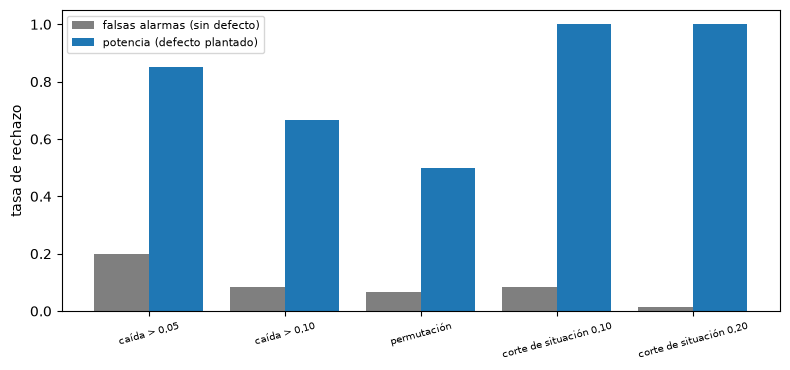

In [12]:
# Tasa de falsas alarmas (gris) y potencia (azul) de las reglas fijas y las corregidas
names = ["caída > 0,05", "caída > 0,10", "permutación", "corte de situación 0,10", "corte de situación 0,20"]
null_rates = [*shift_rates[0.0][0], *situation_rates[0.0]]
power_rates = [*shift_rates[2.0][0], *situation_rates[0.8]]
index = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(index - 0.2, null_rates, width=0.4, color="tab:gray", label="falsas alarmas (sin defecto)")
ax.bar(index + 0.2, power_rates, width=0.4, color="tab:blue", label="potencia (defecto plantado)")
ax.set_xticks(index)
ax.set_xticklabels(names, fontsize=7, rotation=15)
ax.set_ylabel("tasa de rechazo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

En las barras grises el corte fijo de caída 0,05 da una falsa alarma en 0,2000 de las réplicas sin desplazamiento, el
corte 0,10 en 0,0833, la referencia por permutación en 0,0667, el corte de situación 0,10 en 0,0850 y el corte 0,20 en
0,0150. En las barras azules la luz de situación detecta el sesgo plantado en todas las réplicas con ambos cortes
(1,0000), y las reglas de resiliencia detectan el desplazamiento plantado en 0,8500, 0,6667 y 0,5000. Una buena regla tiene
una barra gris corta y una azul alta: el corte 0,20 es el único que cumple ambas en este diseño, y la referencia por
permutación cambia potencia por tamaño.

## Resultados

**Respuesta:** Sí: las correcciones quitan la mayor parte de las falsas alarmas, con un costo de potencia para la regla por permutación en este diseño pequeño. Con datos intercambiables y un nivel nominal de 0,05, la prueba de cobertura binomial rechaza en 0,1587 y 0,3893 de las réplicas cuando la ventana de prueba iguala o supera a la de calibración, contra 0,0440 y 0,0427 de la nula Beta-Binomial. Sin desplazamiento una caída fija sobre 0,05 se activa en 0,2000 de las réplicas y la regla por permutación en 0,0667, mientras que frente a un desplazamiento plantado lo detectan en 0,8500 y 0,5000. El corte de situación 0,20 da una falsa alarma en 0,0150 de las réplicas nulas contra 0,0850 del corte 0,10.

- **La nula binomial hace que la prueba de cobertura rechace demasiado una vez que la ventana de prueba no es pequeña.** Con datos intercambiables y el nivel nominal 0,05, el valor p binomial cae bajo 0,05 en 0,0600 de las réplicas cuando la ventana de prueba es un décimo de la de calibración (error estándar 0,0061), en 0,1587 cuando las dos ventanas son iguales (0,0094) y en 0,3893 cuando la ventana de prueba es cuatro veces la de calibración (0,0126). El valor p Beta-Binomial del motor cae bajo 0,05 en 0,0460, 0,0440 y 0,0427 de ellas (errores estándar de 0,0052 a 0,0054): bajo el nivel nominal en las tres razones, nunca sobre él. Las ventanas versionadas de la Reserva Federal tienen una ventana de calibración de 1.471 empresas contra ventanas de prueba de 3.151 y 12.604, el régimen donde las dos difieren: la ventana base da 0,523 (Beta-Binomial) y 0,313 (binomial), y para la cobertura de 0,8800 del desplazamiento completo el valor p Beta-Binomial es 0,0372 (ámbar) mientras el binomial es 0,000258.
- **Una regla de caída fija se activa sobre un modelo estable; la referencia por permutación no.** Sin cambio, la caída bruta del peor cuarto según el puntaje de cambio tiene una media de 0,0119 y un percentil 95 de 0,1203 sobre 60 réplicas. Una regla "caída sobre 0,05" levanta una falsa alarma en 0,2000 de ellas y "caída sobre 0,10" en 0,0833; la regla por permutación (p como máximo 0,05, con 39 sorteos aquí) en 0,0667, que está dentro del error estándar (0,0281) del nivel nominal. Contra el cambio plantado de 2 desviaciones estándar las tres reglas lo detectan en 0,8500, 0,6667 y 0,5000 de las réplicas. Así, en este diseño pequeño la referencia por permutación mantiene la tasa de falsa alarma cerca de su nivel y lo paga en potencia, porque 250 filas de evaluación y 39 sorteos vuelven gruesa la referencia; los cortes fijos detectan más porque también se activan cuando no hay nada. Los 199 sorteos por omisión del motor y muestras mayores reducen ese costo, y este notebook no lo mide. La fila versionada de la Reserva Federal lee una caída de 0,0857 contra una nula que promedia 0,0007 y tiene un percentil 95 de 0,0243 sobre 199 sorteos: p = 0,005, rojo.
- **El punto de corte 0,20 de la luz de situación elimina la mayoría de las falsas alarmas sin costo en potencia en este diseño.** Sin efecto de grupo la proporción de denunciantes significativos promedia 0,0398, y supera el corte antiguo 0,10 en 0,0850 de las 200 réplicas y el corte 0,20 en 0,0150; con el sesgo plantado la proporción promedia 0,7338 y supera ambos cortes en toda réplica. La medición documentada del propio motor (un tamaño de 0,039 en 0,20 y 0,194 en 0,10) usa otro protocolo y no se reproduce aquí: la dirección coincide, la magnitud no. La fila versionada de Delaware 2018 tiene una proporción de 0,2629 contra el corte 0,2: ámbar.
- **Lo que esta evidencia respalda para BS-10.** Las tres correcciones están en uso en los documentos versionados (ambos valores p conformes lado a lado, 199 sorteos por permutación, el corte 0,2), y las funciones del propio motor sobre datos plantados muestran el tamaño que corrige cada una: 0,1587 y 0,3893 para la prueba de cobertura binomial contra cerca de 0,044 para la Beta-Binomial, 0,2000 y 0,0833 para cortes de caída fijos contra 0,0667 para la referencia por permutación, 0,0850 contra 0,0150 para los dos cortes de situación. Todas las filas versionadas se hornearon con riskvalidation 1.0.1.

Lo que los resultados no muestran: las simulaciones son pequeñas (1.500, 60 y 200 réplicas) y cada tasa lleva el error estándar impreso a su lado; el diseño de cambio tiene pocas filas y 39 sorteos; los conjuntos de tamaño y potencia del propio motor, que son mayores, están en el repositorio del motor y no se corren aquí; los defectos plantados son sintéticos; y una prueba con buen tamaño y potencia sobre una planta no dice todavía nada de una cartera real.

## Resumen

- La nula binomial hace que la prueba de cobertura rechace en 0,0600, 0,1587 y 0,3893 de las réplicas intercambiables con razones de prueba a calibración de 0,1, 1 y 4, mientras la nula Beta-Binomial del motor se queda en 0,0460, 0,0440 y 0,0427.
- Una regla de caída fija del AUC en la peor submuestra levanta una falsa alarma en 0,2000 y 0,0833 de las réplicas sin cambio; la referencia por permutación en 0,0667, con un costo en potencia en este diseño pequeño.
- El punto de corte ámbar 0,20 de la prueba de situación levanta una falsa alarma en 0,0150 de las réplicas nulas contra 0,0850 del corte 0,10, y ambos detectan el sesgo plantado en toda réplica.
- Las filas versionadas de C20 y C21 llevan las correcciones en uso: ambos valores p conformes lado a lado, 199 sorteos por permutación y el corte 0,2, horneadas con riskvalidation 1.0.1.
- Cada tasa se imprime con su error estándar de Monte Carlo; las simulaciones son pequeñas, las plantas sintéticas, y los conjuntos de tamaño y potencia mayores del motor no se corren aquí.

**Qué probar después.** El tema 14 mide el tamaño y la potencia de todo el catálogo del motor sobre defectos plantados, con el mismo método a mayor escala.

## Referencias

- Angelopoulos, A. N. y Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- PiML-Toolbox (Apache-2.0), pruebas de resultados WeakSpot, Overfit, Reliability, Robustness y Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- Phipson, B. y Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Alvarez, J. M. y Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Zieba, M., Tomczak, S. K. y Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data